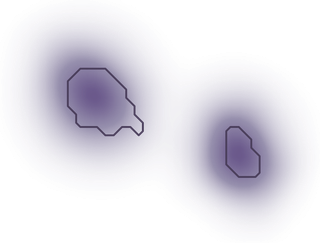

# FOLKLORE tutorial notebook

Andressa Wille  
October 2026

<br clear="left">

This notebook runs FOLKLORE on two jellyfish galaxies in Abell 2744.
Clumps are detected on PSF-matched JWST/NIRCam short-wavelength data
cubes built with [lightstack](https://github.com/AndressaWille/lightstack)
and measured on cubes with all the NIRCam filters.

The first part goes through the steps for one galaxy, with the
diagnostic plots of each step:

1. load the data cube;
2. build the galaxy masks;
3. compute the local contrast map of each filter;
4. detect clumps in every filter;
5. match the detections across filters and keep the clumps found in at
   least three filters;
6. measure the clump sizes and classify the clumps as disk or outside;
7. save the tables and the clump polygons;
8. measure the clump photometry on another cube.

The second part runs the same steps in a loop over all galaxies.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import folklore as fm

plt.rcParams["figure.dpi"] = 100

## Input data and parameters

For each galaxy you need:

* the **data cube** (FITS, shape `(n_filters, ny, nx)`, with WCS and the
  `FILTERn` header keywords);
* the **coordinates of the galaxy centre** (RA, Dec), used to build the
  galaxy body mask;
* the **redshift**, used to convert clump sizes to kpc;
* the cube(s) used for **photometry** (here a cube with all the JWST/NIRCam
  filters, `cube_phot`), which can have a different pixel grid.

Tables and polygons are written to `OUTPUT_DIR`. `mask_level` is the
level of the galaxy body mask chosen by eye in step 6. The data cubes used here are not distributed with
the package: use this notebook as a template with your own cubes and
edit `DATA_DIR` and `GALAXIES` accordingly. The
detection parameters below are the ones used for the galaxies in this
example.

In [2]:
DATA_DIR = Path("/home/andressa/github/jelly-clumps/datacubes/abell2744")

GALAXIES = {
    "J10": {
        "cube": DATA_DIR / "J10" / "datacube_J10_jwst_nircam_sw_psfmatched.fits",
        "cube_phot": DATA_DIR / "J10" / "datacube_J10_jwst_nircam_all_psfmatched.fits",
        "ra": "0:14:16.6358",
        "dec": "-30:23:03.245",
        "z": 0.295,
        "mask_level": -2,
    },
    "J1": {
        "cube": DATA_DIR / "J1" / "datacube_J1_jwst_nircam_sw_psfmatched.fits",
        "cube_phot": DATA_DIR / "J1" / "datacube_J1_jwst_nircam_all_psfmatched.fits",
        "ra": "0:14:28.4945",
        "dec": "-30:23:34.496",
        "z": 0.302,
        "mask_level": -1,
    },
}

PARAMS = {
    # galaxy masks
    "percentiles": (30, 90),
    # local contrast map
    "sigma_smooth": None,
    "bkg_size": 15,
    "sigma_size": 15,
    # detection
    "sigma_center": 3.5,
    "sigma_outer": 4.0,
    "sigma_split": None,
    "min_area": 3,
    # cross-filter matching
    "min_overlap": 0.20,
    "min_filters": 3,
    # galaxy body mask (disk/outside classification)
    "region_sigma_smooth": 1.5,
    "region_nsigma": 3,
    "region_nlevels": 60,
    "region_connectivity": 4,
    # photometry: background ring (pixels of the photometry cube)
    "inner_radius": 0,
    "outer_radius": 2,
}

OUTPUT_DIR = Path("output")

## Example with one galaxy

The first galaxy of `GALAXIES` is analysed step by step.

### 1. Data cube

`load_datacube` returns the cube `(n_filters, ny, nx)`, its header and WCS,
and a dictionary with the cube index of each filter (read from the
`FILTERn` header keywords).

In [3]:
name = list(GALAXIES)[0]
galaxy = GALAXIES[name]

data_cube, header, wcs, filters = fm.load_datacube(galaxy["cube"])

print("Cube shape:", data_cube.shape)
print("Filters:", list(filters))
print(f"Pixel scale: {fm.pixel_scale_arcsec(wcs):.3f} arcsec/pixel")

Cube shape: (9, 211, 160)
Filters: ['F070W', 'F090W', 'F115W', 'F140M', 'F150W', 'F162M', 'F182M', 'F200W', 'F210M']
Pixel scale: 0.020 arcsec/pixel


### 2. Galaxy masks

The cube is collapsed along the filter axis and thresholded at two
percentiles. The lowest-percentile mask is the region where clumps are
searched for; the highest one is the galaxy centre, where `sigma_center`
is used instead of `sigma_outer`.

> *This step is still being revised.*

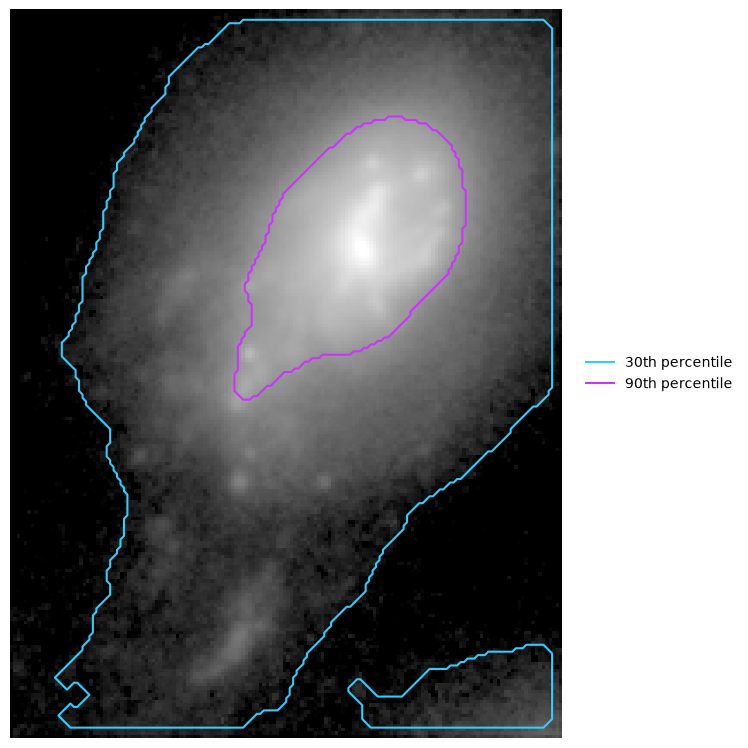

In [4]:
image = fm.collapse_cube(data_cube)
galaxy_masks = fm.build_galaxy_masks(image, percentiles=PARAMS["percentiles"])

fm.plot_galaxy_masks(galaxy_masks)

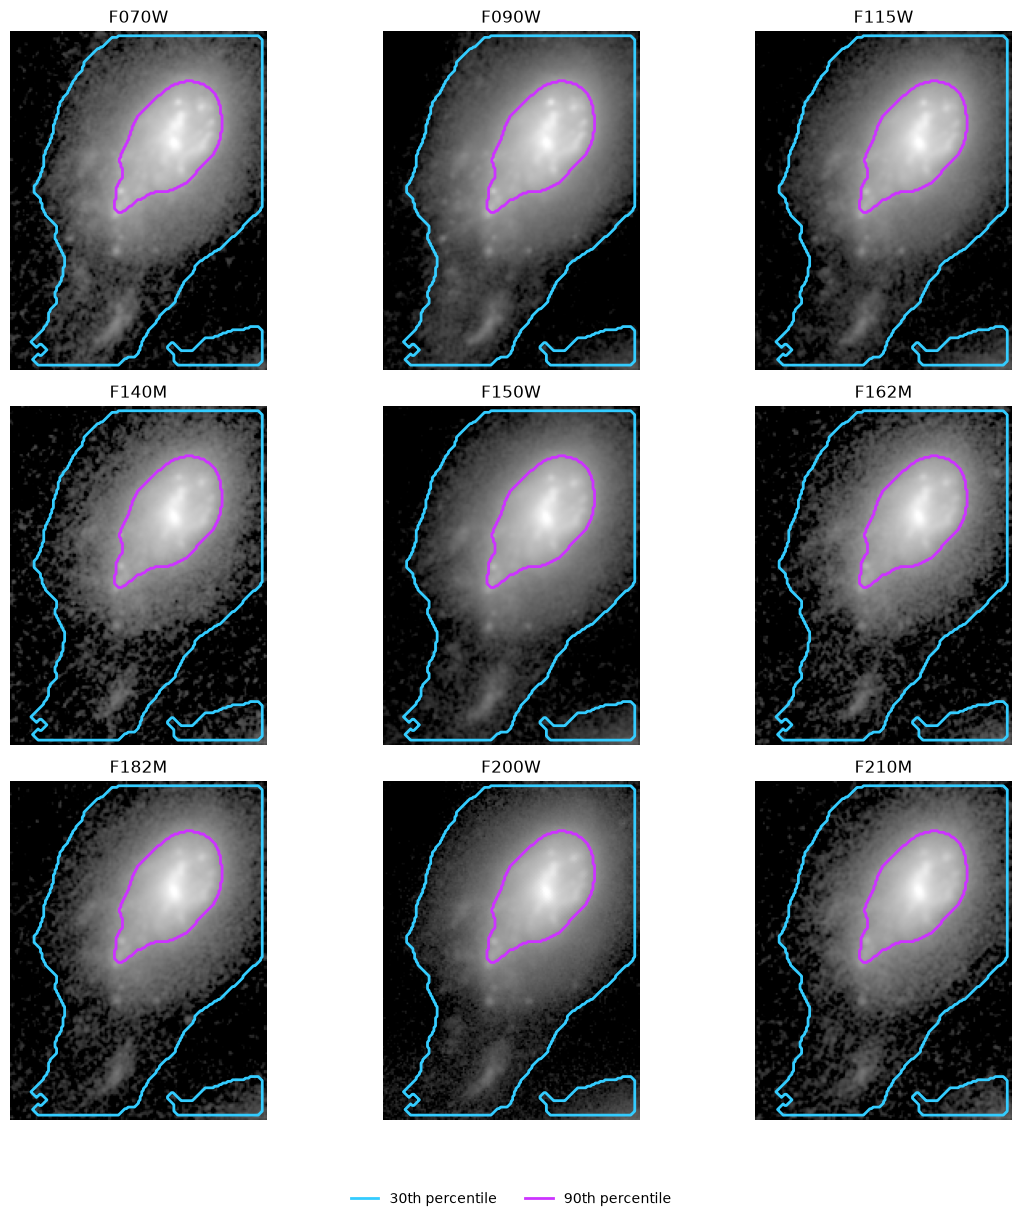

In [5]:
fm.plot_masks_filters(data_cube, filters, galaxy_masks)

### 3. Local contrast map

For each filter, the background $B$ is a running median of the image and
the local noise $\sigma_\mathrm{local}$ is the square root of the running
median of the squared residuals. The contrast map

$$C = \frac{I - B}{\sigma_\mathrm{local}}$$

gives the significance of each pixel above its surroundings. Below are
the steps for one filter (F150W) as an example. It is good practice to
check them in every filter of the cube: uncomment the next cell to do so.

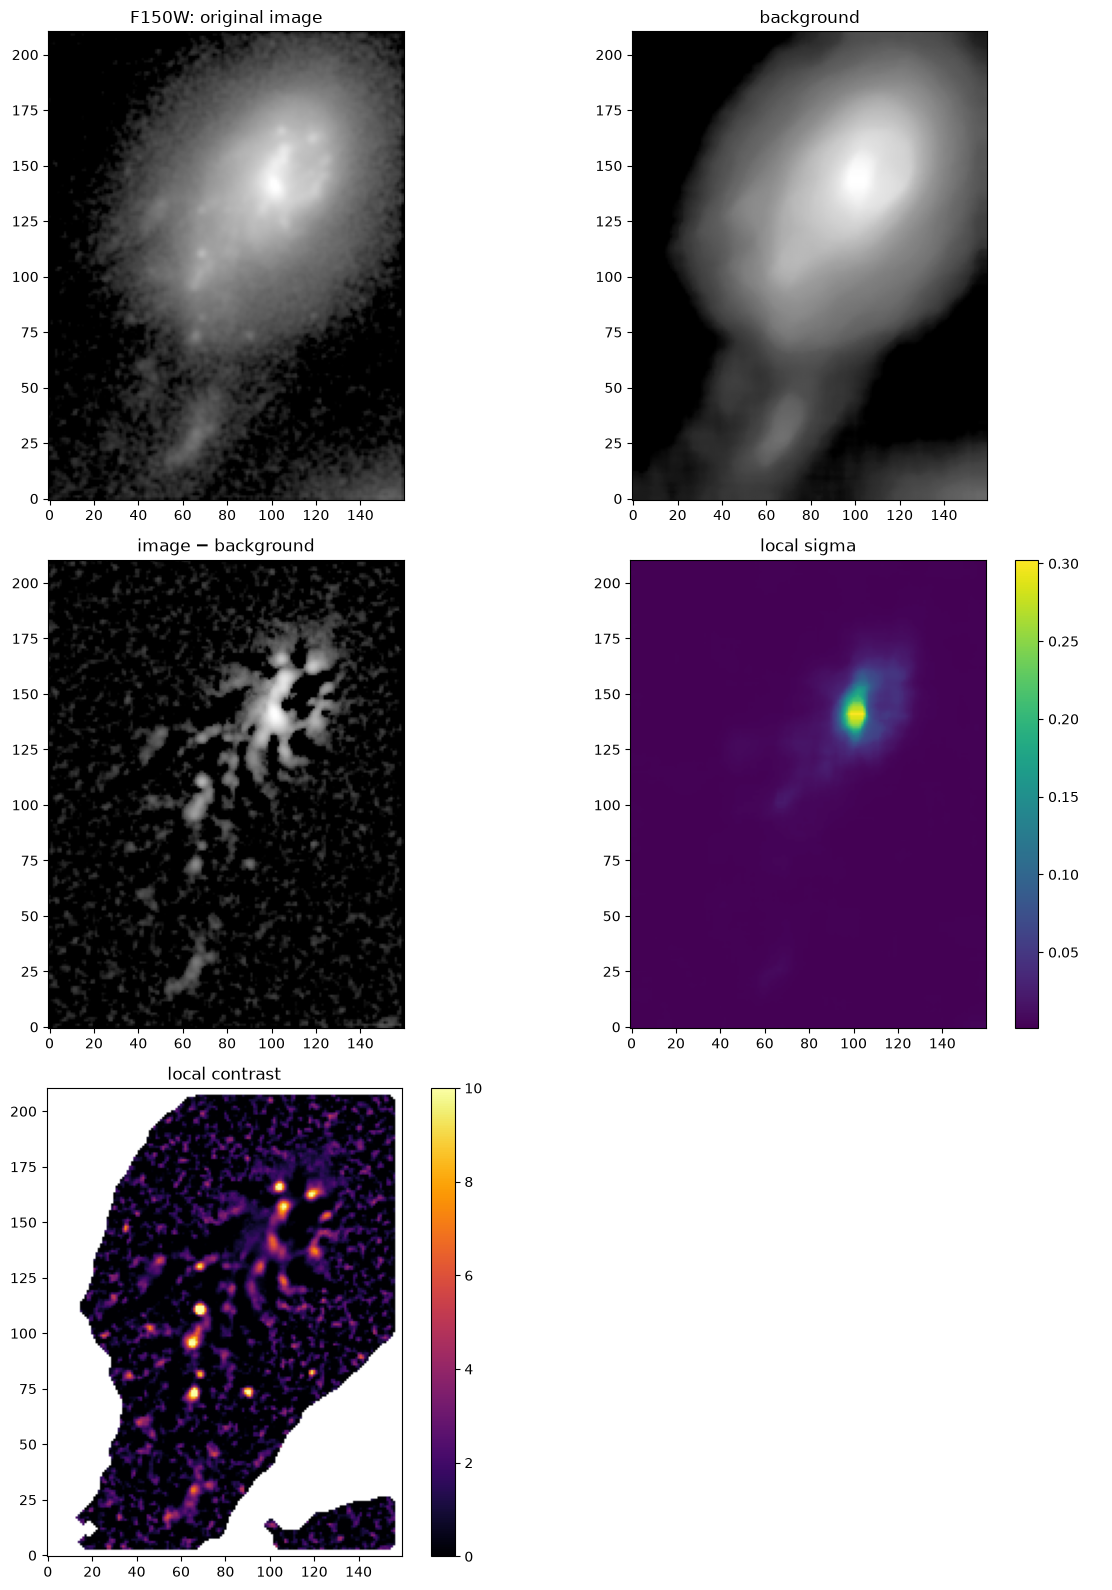

In [6]:
filt = "F150W"
gal_mask = galaxy_masks["masks"][min(PARAMS["percentiles"])]

fm.plot_contrast_steps(
    data_cube[filters[filt]], gal_mask, filt_name=filt,
    sigma_smooth=PARAMS["sigma_smooth"],
    bkg_size=PARAMS["bkg_size"], sigma_size=PARAMS["sigma_size"],
)

In [7]:
# for filt in filters:
#     fm.plot_contrast_steps(
#         data_cube[filters[filt]], gal_mask, filt_name=filt,
#         sigma_smooth=PARAMS["sigma_smooth"],
#         bkg_size=PARAMS["bkg_size"], sigma_size=PARAMS["sigma_size"],
#     )

Contours of the contrast map at a few significance levels help choosing
the detection thresholds. Check them in **all** filters: a threshold that
works in one band may pick up noise, or miss faint clumps, in another.

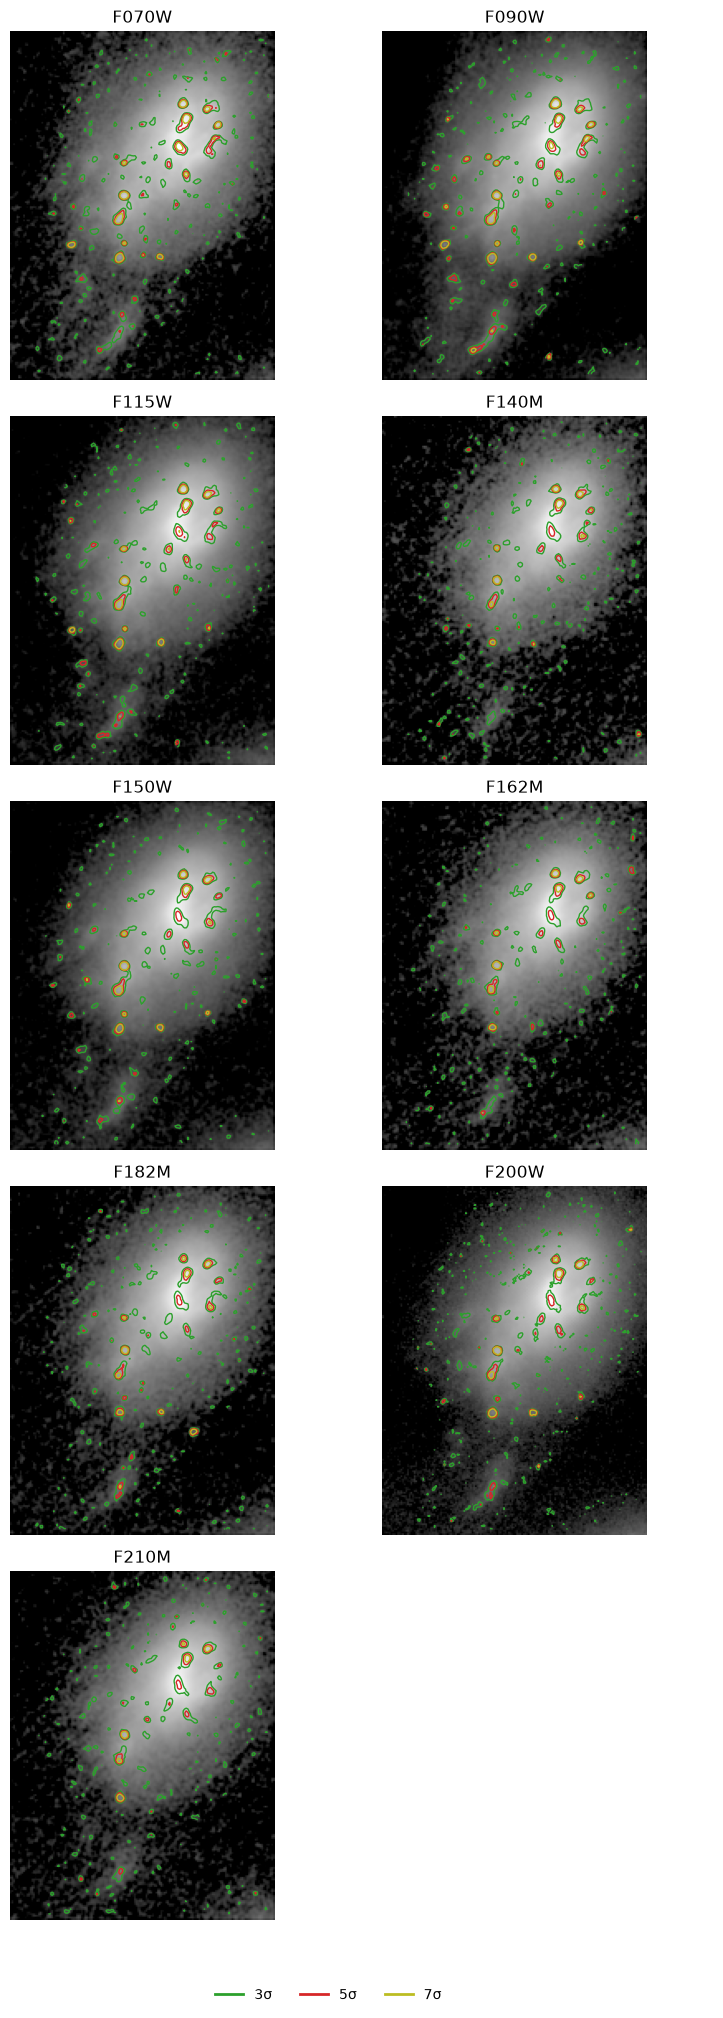

In [8]:
fm.plot_contrast_levels_filters(
    data_cube, filters, galaxy_masks, levels=(3, 5, 7), ncols=2,
    sigma_smooth=PARAMS["sigma_smooth"],
    bkg_size=PARAMS["bkg_size"], sigma_size=PARAMS["sigma_size"],
)

### 4. Detection in every filter

Pixels above `sigma_center` (centre) or `sigma_outer` (rest of the
galaxy) are grouped into connected regions, and regions smaller than
`min_area` pixels are discarded.

In [9]:
clumps_by_filter, pixels_by_filter, pixels_all = fm.build_clump_dataframes(
    data_cube, filters, galaxy_masks,
    sigma_center=PARAMS["sigma_center"],
    sigma_outer=PARAMS["sigma_outer"],
    sigma_split=PARAMS["sigma_split"],
    min_area=PARAMS["min_area"],
    sigma_smooth=PARAMS["sigma_smooth"],
    bkg_size=PARAMS["bkg_size"],
    sigma_size=PARAMS["sigma_size"],
)

F070W: candidate regions = 88


F090W: candidate regions = 96


F115W: candidate regions = 91


F140M: candidate regions = 86


F150W: candidate regions = 74


F162M: candidate regions = 76


F182M: candidate regions = 84


F200W: candidate regions = 133


F210M: candidate regions = 74


In [10]:
clumps_by_filter["F150W"].head()

,filter,label,area_pix,x0,y0
0,F150W,1,3,27.666667,3.666667
1,F150W,6,10,54.300000,17.500000
2,F150W,10,14,65.857143,29.285714
3,F150W,11,4,87.500000,29.500000
4,F150W,12,6,73.000000,31.500000


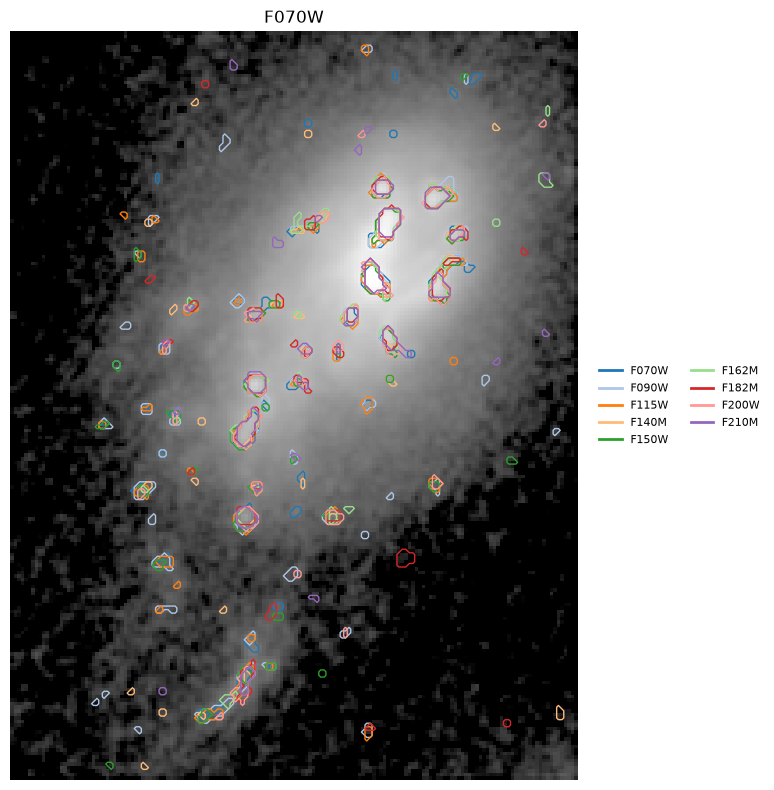

In [11]:
fm.plot_clumps_filters(data_cube, filters, pixels_by_filter)

### 5. Cross-filter matching

Two detections in different filters are linked when their pixel sets
overlap by at least `min_overlap` (relative to the smaller one). The
connected groups of linked detections are the physical clumps; only those
found in at least `min_filters` filters are kept.

In [12]:
clump_pixels = fm.build_clump_pixel_sets(pixels_all)
df_overlap = fm.compute_clump_overlaps(clump_pixels, min_overlap=PARAMS["min_overlap"])
G = fm.build_overlap_graph(df_overlap)
df_components = fm.find_final_clumps(G, min_filters=PARAMS["min_filters"])

df_clumps_final, df_pixels_final = fm.build_final_clump_dataframes(
    clumps_by_filter, pixels_by_filter, df_components)

print("Clumps found in at least", PARAMS["min_filters"], "filters:",
      df_components["clump_id"].nunique())

Clumps found in at least 3 filters: 38


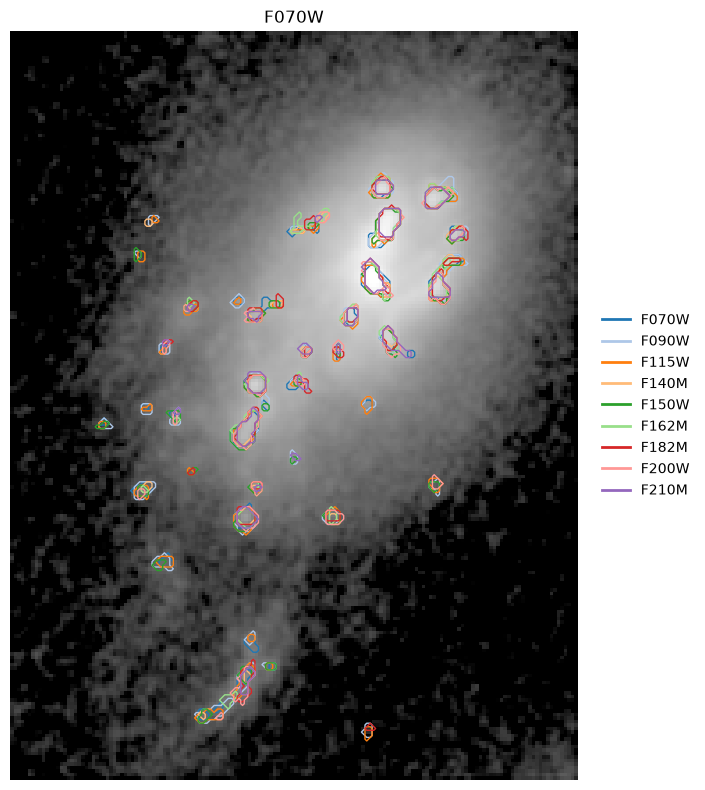

In [13]:
fm.plot_final_clumps(data_cube, filters, df_pixels_final)

The final mask of each clump is the union of its pixels in all filters.

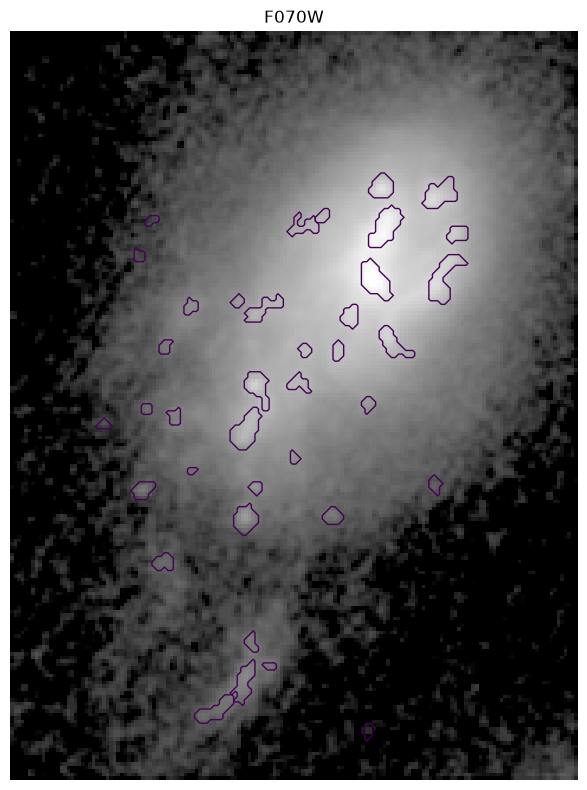

In [14]:
union_masks = fm.build_union_masks(df_pixels_final, data_cube.shape[1:])

fm.plot_union_clumps(data_cube, filters, union_masks)

### 6. Clump properties and disk/outside classification

Clump sizes are measured on the union masks and converted to kpc with the
redshift of the galaxy.

Each clump is then classified as **disk** when its centroid falls inside
the galaxy body mask and **outside** otherwise. The mask is grown from the
galaxy centre (given by its RA and Dec) by lowering an intensity threshold
on the collapsed image, which gives one mask per threshold level, from the
core to the outskirts.

In [15]:
df_union_pixels, df_union_clumps = fm.compute_clump_geometry(
    union_masks, fm.pixel_scale_arcsec(wcs), wcs=fm.get_celestial_wcs(wcs))
df_union_clumps = fm.add_physical_sizes(df_union_clumps, z=galaxy["z"])

center = fm.skycoord_to_pixel(galaxy["ra"], galaxy["dec"], wcs)

region = fm.build_galaxy_region(
    image, center=center,
    sigma_smooth=PARAMS["region_sigma_smooth"],
    nsigma=PARAMS["region_nsigma"],
    nlevels=PARAMS["region_nlevels"],
    connectivity=PARAMS["region_connectivity"],
)

print(f"Centre (x, y): ({center[0]:.1f}, {center[1]:.1f})")
print("Number of mask levels:", len(region["masks"]))

Centre (x, y): (102.1, 142.0)
Number of mask levels: 58


The last levels are where the mask grows from the bright disk into the
outskirts and, eventually, into the tail. Choose the level that best
follows the disk; each panel shows the resulting number of disk and
outside clumps. For this galaxy we use level `-2` (`mask_level` in `GALAXIES`).

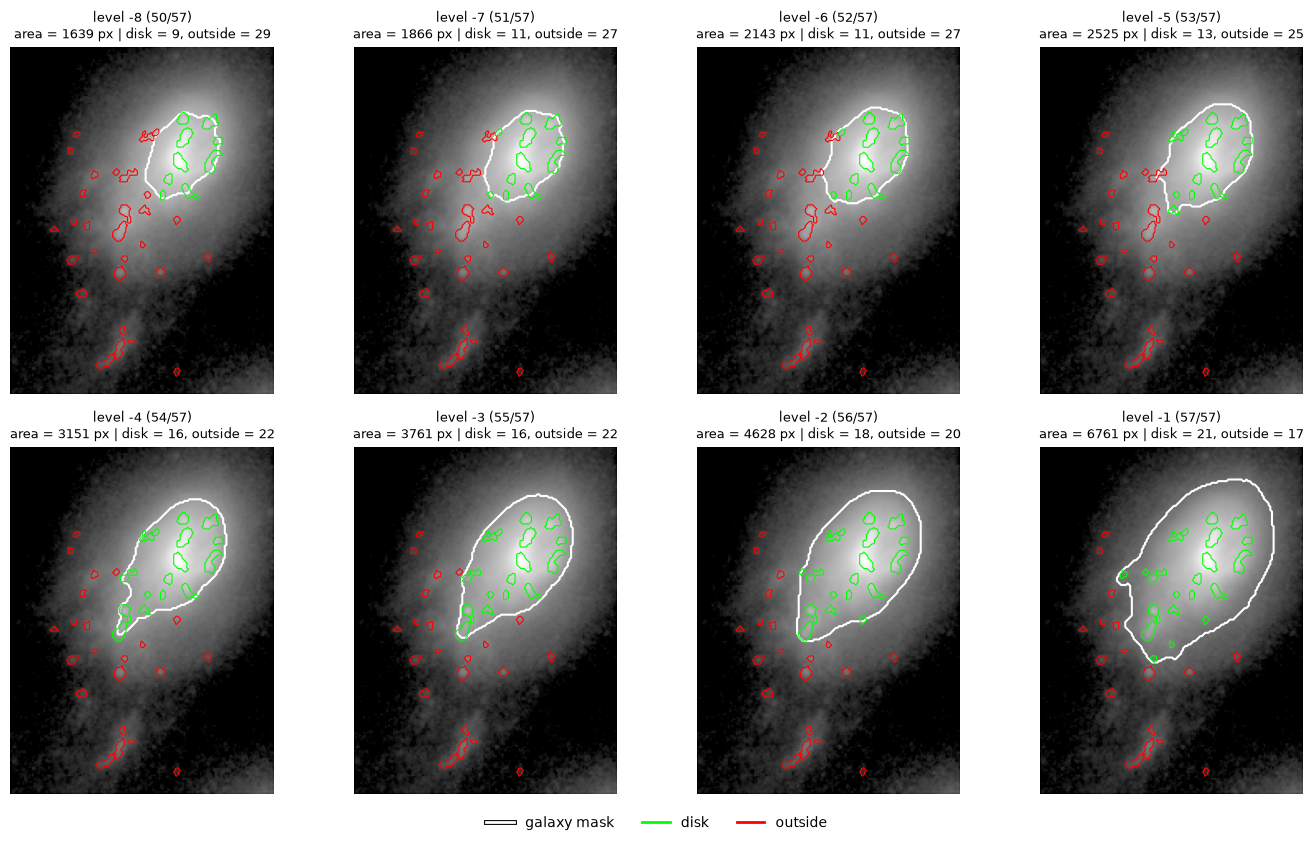

In [16]:
fm.plot_galaxy_region_levels(image, region, union_masks, df_union_clumps)

> **Automatic alternative.** `build_galaxy_region` can also select the
> level by itself: with `min_fraction` the lowest threshold is a fraction
> of the peak, and with `growth_factor` the growth stops at the level
> before the area jumps (the mask leaking into the tail or the background).
> The selected mask is `region["mask"]`. Always check the result: a single
> pair of parameters does not suit every galaxy (with `min_fraction=0.02`
> and `growth_factor=1.5`, the mask of this galaxy is similar to level
> `-2`, but the mask of the second galaxy of this example is smaller than
> the one chosen by eye).

In [17]:
# region_auto = fm.build_galaxy_region(
#     image, center=center,
#     sigma_smooth=PARAMS["region_sigma_smooth"],
#     nlevels=PARAMS["region_nlevels"],
#     connectivity=PARAMS["region_connectivity"],
#     min_fraction=0.02, growth_factor=1.5,
# )
# print(region_auto["stop_reason"], region_auto["mask"].sum(), "px")

component
outside    20
disk       18
Name: count, dtype: int64


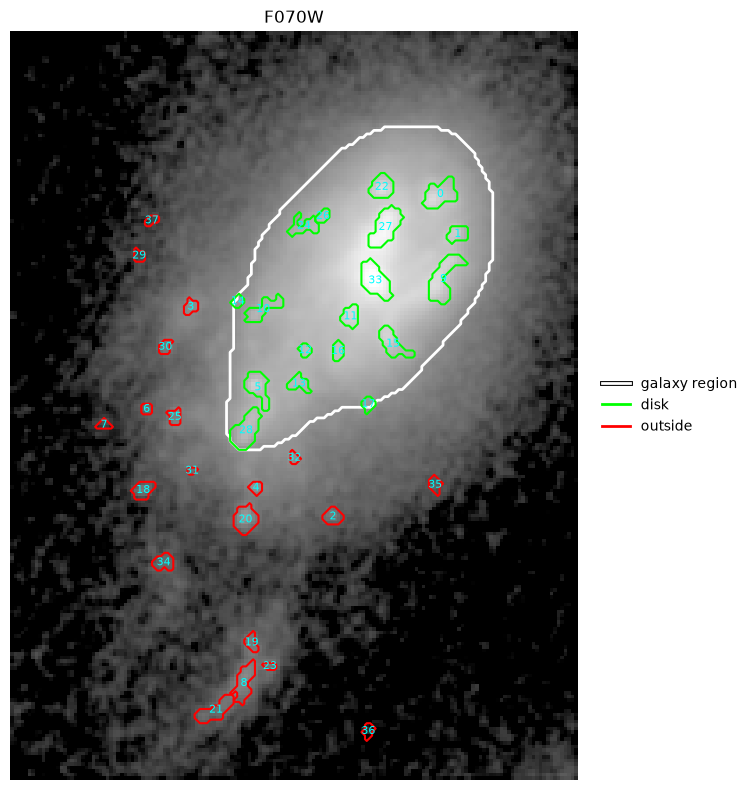

In [18]:
galaxy_mask = region["masks"][galaxy["mask_level"]]
df_union_clumps = fm.classify_clumps(df_union_clumps, galaxy_mask)

print(df_union_clumps["component"].value_counts())
fm.plot_classify_clumps(data_cube, filters, union_masks, galaxy_mask, df_union_clumps)

In [19]:
df_union_clumps.head()

,clump_id,area_pix,area_arcsec2,r_eff_arcsec,x0,y0,area_kpc2,r_eff_kpc,inside,component
0,0,55,0.0220,0.083683,120.763636,164.545455,0.426432,0.368426,True,disk
1,1,23,0.0092,0.054115,125.652174,153.304348,0.178326,0.238250,True,disk
2,2,22,0.0088,0.052926,90.500000,73.727273,0.170573,0.233013,False,outside
3,3,14,0.0056,0.042220,50.428571,132.785714,0.108546,0.185880,False,outside
4,4,11,0.0044,0.037424,68.818182,81.818182,0.085286,0.164765,False,outside


### 7. Outputs: tables and polygons

The clump catalogue (`*_properties.csv`, one row per clump) and the pixel
table (`*_pixels.csv`, one row per clump pixel, with its RA and Dec) are
the main outputs. The pixel table carries the clump definition to the
photometry stage.

The clump masks are also converted into polygons and saved as GeoJSON, in
pixel coordinates and in sky coordinates (RA, Dec; CRS `EPSG:4326`). The
polygons can be opened in QGIS or DS9-like tools, or reused to draw the
clumps on other images. All columns of the catalogue are copied to the
polygons.

In [20]:
import warnings

output_dir = OUTPUT_DIR / name
output_dir.mkdir(parents=True, exist_ok=True)

df_union_clumps.to_csv(output_dir / f"{name}_properties.csv", index=False)
df_union_pixels.to_csv(output_dir / f"{name}_pixels.csv", index=False)

gdf_pix = fm.build_clump_geodataframe(union_masks, df_union_clumps)
gdf_sky = fm.build_clump_geodataframe_sky(union_masks, df_union_clumps, wcs)

# pixel coordinates have no CRS; silence the warning about it
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="'crs' was not provided")
    gdf_pix.to_file(output_dir / f"clumps_{name}_pixels.geojson", driver="GeoJSON")
gdf_sky.to_file(output_dir / f"clumps_{name}_sky.geojson", driver="GeoJSON")

gdf_sky[["clump_id", "component", "r_eff_kpc", "geometry"]].head()

,clump_id,component,r_eff_kpc,geometry
0,0,disk,0.368426,"POLYGON ((3.56917 -30.38408, 3.56918 -30.38408..."
1,1,disk,0.238250,"POLYGON ((3.56915 -30.38416, 3.56916 -30.38416..."
2,2,outside,0.233013,"POLYGON ((3.56939 -30.3846, 3.56939 -30.3846, ..."
3,3,outside,0.185880,"POLYGON ((3.56965 -30.38427, 3.56965 -30.38427..."
4,4,outside,0.164765,"POLYGON ((3.56952 -30.38456, 3.56953 -30.38456..."


The polygons in pixel coordinates, drawn over the reference image and
coloured by component:

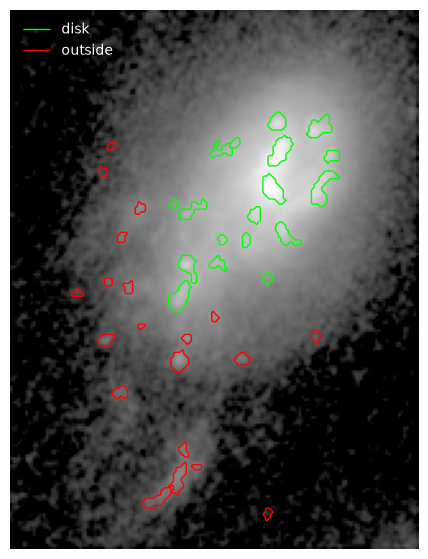

In [21]:
ref_image = data_cube[0]
norm = fm.plotting._resolve_norm(ref_image)

fig, ax = plt.subplots(figsize=(6, 7))
ax.imshow(ref_image, origin="lower", cmap="gray", norm=norm)
for component, color in [("disk", "lime"), ("outside", "red")]:
    gdf_pix[gdf_pix["component"] == component].boundary.plot(
        ax=ax, color=color, linewidth=1, label=component)
ax.legend(frameon=False, loc="upper left", labelcolor="white")
ax.set_axis_off()
plt.show()

### 8. Photometry on the cube with all NIRCam filters

Because the clumps are stored in sky coordinates, they can be measured on
any cube, even with a different pixel grid. Here we use a PSF-matched cube
with all the NIRCam filters (F070W–F480M) on the 0.04″/pixel grid of the
long-wavelength channel, while detection was done on the 0.02″/pixel
short-wavelength cube. The same steps apply to HST cubes; the tables can
then be concatenated before building the SED table.

Each clump pixel is placed on the nearest pixel of the new grid:

Cube shape: (20, 105, 79)
Filters: ['F070W', 'F090W', 'F115W', 'F140M', 'F150W', 'F162M', 'F182M', 'F200W', 'F210M', 'F250M', 'F277W', 'F300M', 'F335M', 'F356W', 'F360M', 'F410M', 'F430M', 'F444W', 'F460M', 'F480M']
Pixel scale: 0.040 arcsec/pixel


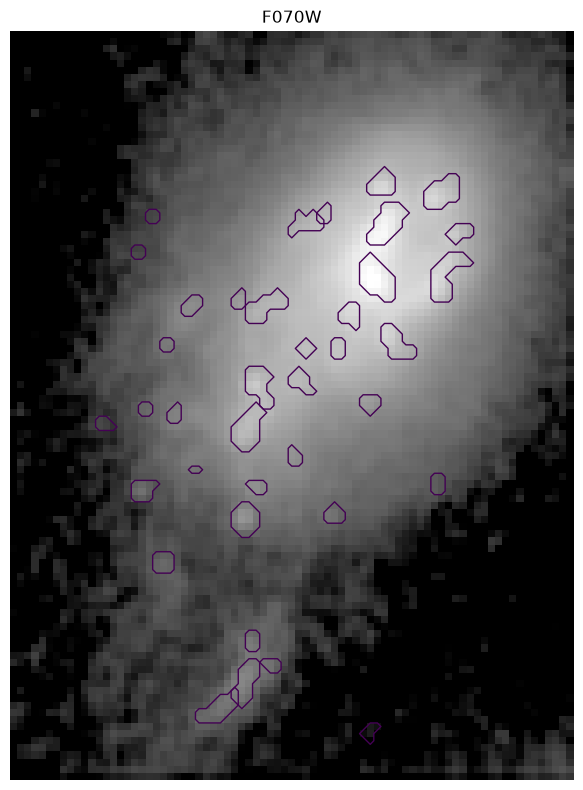

In [22]:
data_cube_phot, header_phot, wcs_phot, filters_phot = fm.load_datacube(galaxy["cube_phot"])
print("Cube shape:", data_cube_phot.shape)
print("Filters:", list(filters_phot))
print(f"Pixel scale: {fm.pixel_scale_arcsec(wcs_phot):.3f} arcsec/pixel")

union_masks_phot = fm.reproject_clump_masks_sky(
    df_union_pixels, wcs_phot, data_cube_phot.shape[1:])

fm.plot_union_clumps(data_cube_phot, filters_phot, union_masks_phot)

The local background of each clump is the median in a ring around it
(`inner_radius` to `outer_radius` pixels from the clump border, excluding
other clumps). The flux is the sum inside the clump minus the background
times the number of pixels; the error is the standard deviation in the ring
times the square root of the number of pixels.

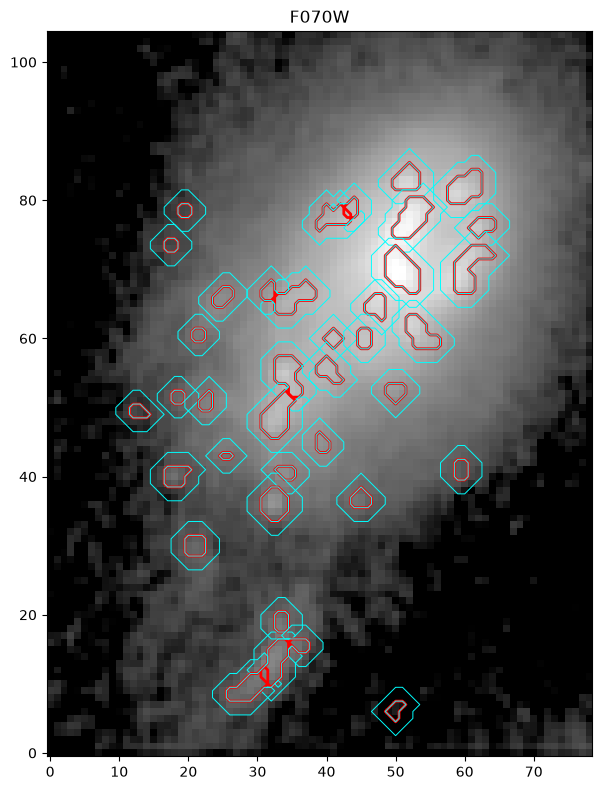

In [23]:
ring_masks_phot = fm.build_background_rings(
    union_masks_phot,
    inner_radius=PARAMS["inner_radius"],
    outer_radius=PARAMS["outer_radius"],
)

fm.plot_clump_rings(data_cube_phot, filters_phot, union_masks_phot, ring_masks_phot)

The flux unit of one pixel must be given; here it is read from the `BUNIT`
keyword of the cube (`10 nJy`). Fluxes are returned in Jy.

In [24]:
import astropy.units as u

flux_unit = u.Unit(header_phot["BUNIT"])
print("Pixel unit:", flux_unit)

df_flux = fm.compute_clump_photometry(
    union_masks_phot, ring_masks_phot, data_cube_phot, filters_phot, flux_unit=flux_unit)

df_flux.head()

Pixel unit: 10 nJy


,clump_id,filter,flux,flux_err,n_pix
0,0,F070W,7.330017e-08,1.439762e-08,19
1,1,F070W,2.194905e-08,9.348929e-09,8
2,2,F070W,2.299729e-09,5.535129e-10,7
3,3,F070W,3.100339e-09,7.057540e-10,7
4,4,F070W,2.454055e-09,8.300244e-10,5


Finally, the long table is converted into the wide format used for SED
fitting, with one row per clump and one flux and error column per filter
(sorted by wavelength).

In [25]:
df_sed = fm.sed_fitting_dataframe(df_flux, filter_order=fm.DEFAULT_FILTER_ORDER)
df_sed.to_csv(output_dir / f"{name}_sed_input.csv", index=False)

df_sed.head()

,clump_id,F070W,F090W,F115W,F140M,F150W,F162M,F182M,F200W,F210M,...,err_F277W,err_F300M,err_F335M,err_F356W,err_F360M,err_F410M,err_F430M,err_F444W,err_F460M,err_F480M
0,0,7.330017e-08,8.545611e-08,1.051885e-07,9.943484e-08,1.024495e-07,1.117070e-07,1.036676e-07,1.123923e-07,1.124666e-07,...,2.794418e-08,2.408608e-08,2.075024e-08,2.016829e-08,2.056542e-08,2.696523e-08,3.943798e-08,2.557648e-08,2.207921e-08,2.010547e-08
1,1,2.194905e-08,3.118304e-08,2.817883e-08,2.774582e-08,2.328362e-08,2.517312e-08,2.503445e-08,2.266444e-08,2.508683e-08,...,1.464881e-08,1.346749e-08,1.185822e-08,1.119299e-08,1.136560e-08,1.589011e-08,2.477792e-08,1.492890e-08,1.294941e-08,1.109423e-08
2,2,2.299729e-09,2.297058e-09,3.969694e-09,2.100436e-09,2.217618e-09,3.252457e-09,3.379778e-09,2.537698e-09,3.011716e-09,...,6.258660e-10,4.937447e-10,4.563523e-10,3.372103e-10,6.452801e-10,5.691456e-10,5.519235e-10,2.698810e-10,1.058141e-09,9.878033e-10
3,3,3.100339e-09,3.489150e-09,3.921570e-09,4.052089e-09,3.001969e-09,3.003797e-09,4.446291e-09,3.263841e-09,2.658711e-09,...,1.060274e-09,9.385798e-10,1.061665e-09,7.486106e-10,8.764208e-10,1.061916e-09,2.225911e-09,1.080918e-09,1.347741e-09,1.081431e-09
4,4,2.454055e-09,2.627902e-09,2.949869e-09,2.146289e-09,1.821009e-09,2.202820e-09,2.786697e-09,2.213503e-09,2.048500e-09,...,6.153441e-10,5.174102e-10,6.910413e-10,5.485547e-10,6.731473e-10,5.093570e-10,5.315099e-10,4.235335e-10,8.477276e-10,1.150683e-09


## Looping over several galaxies

The same steps, written as one function and run for every galaxy in
`GALAXIES`. Only the final classification and the photometry tables are
shown; the tables and polygons of each galaxy are written to
`OUTPUT_DIR/<name>/`. The level of the galaxy body mask (`mask_level`)
must be chosen beforehand for each galaxy, with
`fm.plot_galaxy_region_levels` as in step 6.

In [26]:
import warnings

import astropy.units as u
from IPython.display import display


def run_galaxy(name, galaxy, params, output_dir):
    """Detection, classification, outputs and photometry of one galaxy."""
    output_dir.mkdir(parents=True, exist_ok=True)

    # 1-2. data cube and galaxy masks
    data_cube, header, wcs, filters = fm.load_datacube(galaxy["cube"])
    image = fm.collapse_cube(data_cube)
    galaxy_masks = fm.build_galaxy_masks(image, percentiles=params["percentiles"])

    # 3-4. detection in every filter
    clumps_by_filter, pixels_by_filter, pixels_all = fm.build_clump_dataframes(
        data_cube, filters, galaxy_masks,
        sigma_center=params["sigma_center"],
        sigma_outer=params["sigma_outer"],
        sigma_split=params["sigma_split"],
        min_area=params["min_area"],
        sigma_smooth=params["sigma_smooth"],
        bkg_size=params["bkg_size"],
        sigma_size=params["sigma_size"],
        verbose=False,
    )

    # 5. cross-filter matching
    df_overlap = fm.compute_clump_overlaps(
        fm.build_clump_pixel_sets(pixels_all), min_overlap=params["min_overlap"])
    df_components = fm.find_final_clumps(
        fm.build_overlap_graph(df_overlap), min_filters=params["min_filters"])
    _, df_pixels_final = fm.build_final_clump_dataframes(
        clumps_by_filter, pixels_by_filter, df_components)
    union_masks = fm.build_union_masks(df_pixels_final, data_cube.shape[1:])

    # 6. sizes and disk/outside classification
    df_union_pixels, df_union_clumps = fm.compute_clump_geometry(
        union_masks, fm.pixel_scale_arcsec(wcs), wcs=fm.get_celestial_wcs(wcs))
    df_union_clumps = fm.add_physical_sizes(df_union_clumps, z=galaxy["z"])

    region = fm.build_galaxy_region(
        image, center=fm.skycoord_to_pixel(galaxy["ra"], galaxy["dec"], wcs),
        sigma_smooth=params["region_sigma_smooth"],
        nsigma=params["region_nsigma"],
        nlevels=params["region_nlevels"],
        connectivity=params["region_connectivity"],
    )
    galaxy_mask = region["masks"][galaxy["mask_level"]]
    df_union_clumps = fm.classify_clumps(df_union_clumps, galaxy_mask)

    # 7. tables and polygons
    df_union_clumps.to_csv(output_dir / f"{name}_properties.csv", index=False)
    df_union_pixels.to_csv(output_dir / f"{name}_pixels.csv", index=False)
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message="'crs' was not provided")
        fm.build_clump_geodataframe(union_masks, df_union_clumps).to_file(
            output_dir / f"clumps_{name}_pixels.geojson", driver="GeoJSON")
    fm.build_clump_geodataframe_sky(union_masks, df_union_clumps, wcs).to_file(
        output_dir / f"clumps_{name}_sky.geojson", driver="GeoJSON")

    # 8. photometry on the photometry cube
    cube_phot, header_phot, wcs_phot, filters_phot = fm.load_datacube(galaxy["cube_phot"])
    masks_phot = fm.reproject_clump_masks_sky(
        df_union_pixels, wcs_phot, cube_phot.shape[1:])
    rings_phot = fm.build_background_rings(
        masks_phot, inner_radius=params["inner_radius"],
        outer_radius=params["outer_radius"])
    df_flux = fm.compute_clump_photometry(
        masks_phot, rings_phot, cube_phot, filters_phot,
        flux_unit=u.Unit(header_phot["BUNIT"]))
    df_sed = fm.sed_fitting_dataframe(df_flux, filter_order=fm.DEFAULT_FILTER_ORDER)
    df_sed.to_csv(output_dir / f"{name}_sed_input.csv", index=False)

    return dict(data_cube=data_cube, filters=filters, union_masks=union_masks,
                galaxy_mask=galaxy_mask, df_union_clumps=df_union_clumps,
                df_sed=df_sed)

In [27]:
results = {}

for name, galaxy in GALAXIES.items():
    results[name] = run_galaxy(name, galaxy, PARAMS, OUTPUT_DIR / name)
    counts = results[name]["df_union_clumps"]["component"].value_counts()
    print(f"{name}: {len(results[name]['union_masks'])} clumps "
          f"(disk = {counts.get('disk', 0)}, outside = {counts.get('outside', 0)})")

J10: 38 clumps (disk = 18, outside = 20)


J1: 120 clumps (disk = 43, outside = 77)


Final disk/outside classification of each galaxy:

J10


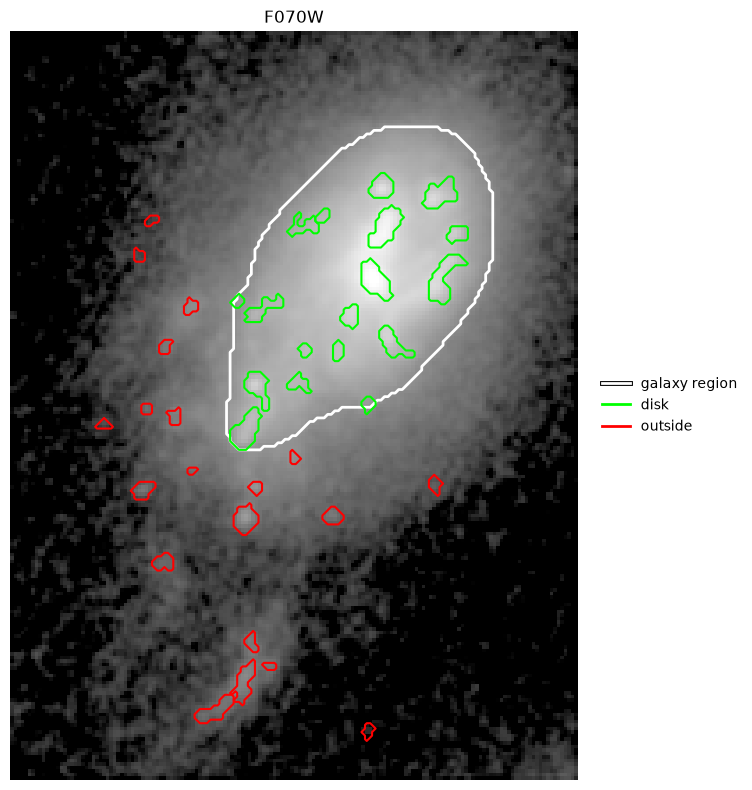

J1


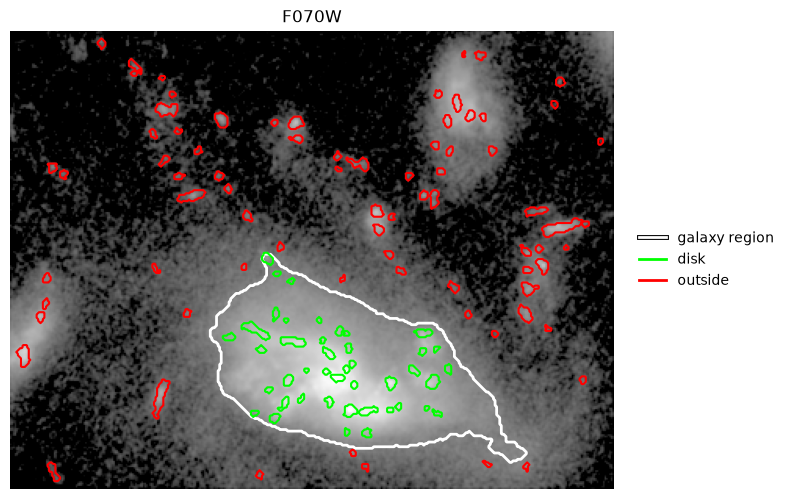

In [28]:
for name, res in results.items():
    print(name)
    fm.plot_classify_clumps(
        res["data_cube"], res["filters"], res["union_masks"],
        res["galaxy_mask"], res["df_union_clumps"], show_ids=False)

Photometry tables (fluxes in Jy) ready for SED fitting:

In [29]:
for name, res in results.items():
    print(name)
    display(res["df_sed"].head())

J10


,clump_id,F070W,F090W,F115W,F140M,F150W,F162M,F182M,F200W,F210M,...,err_F277W,err_F300M,err_F335M,err_F356W,err_F360M,err_F410M,err_F430M,err_F444W,err_F460M,err_F480M
0,0,7.330017e-08,8.545611e-08,1.051885e-07,9.943484e-08,1.024495e-07,1.117070e-07,1.036676e-07,1.123923e-07,1.124666e-07,...,2.794418e-08,2.408608e-08,2.075024e-08,2.016829e-08,2.056542e-08,2.696523e-08,3.943798e-08,2.557648e-08,2.207921e-08,2.010547e-08
1,1,2.194905e-08,3.118304e-08,2.817883e-08,2.774582e-08,2.328362e-08,2.517312e-08,2.503445e-08,2.266444e-08,2.508683e-08,...,1.464881e-08,1.346749e-08,1.185822e-08,1.119299e-08,1.136560e-08,1.589011e-08,2.477792e-08,1.492890e-08,1.294941e-08,1.109423e-08
2,2,2.299729e-09,2.297058e-09,3.969694e-09,2.100436e-09,2.217618e-09,3.252457e-09,3.379778e-09,2.537698e-09,3.011716e-09,...,6.258660e-10,4.937447e-10,4.563523e-10,3.372103e-10,6.452801e-10,5.691456e-10,5.519235e-10,2.698810e-10,1.058141e-09,9.878033e-10
3,3,3.100339e-09,3.489150e-09,3.921570e-09,4.052089e-09,3.001969e-09,3.003797e-09,4.446291e-09,3.263841e-09,2.658711e-09,...,1.060274e-09,9.385798e-10,1.061665e-09,7.486106e-10,8.764208e-10,1.061916e-09,2.225911e-09,1.080918e-09,1.347741e-09,1.081431e-09
4,4,2.454055e-09,2.627902e-09,2.949869e-09,2.146289e-09,1.821009e-09,2.202820e-09,2.786697e-09,2.213503e-09,2.048500e-09,...,6.153441e-10,5.174102e-10,6.910413e-10,5.485547e-10,6.731473e-10,5.093570e-10,5.315099e-10,4.235335e-10,8.477276e-10,1.150683e-09


J1


,clump_id,F070W,F090W,F115W,F140M,F150W,F162M,F182M,F200W,F210M,...,err_F277W,err_F300M,err_F335M,err_F356W,err_F360M,err_F410M,err_F430M,err_F444W,err_F460M,err_F480M
0,0,2.345856e-09,3.770570e-09,3.384518e-09,1.743660e-09,2.809727e-09,9.101474e-10,1.800180e-09,2.746884e-09,2.368983e-09,...,2.651973e-10,3.621233e-10,4.233212e-10,1.641416e-10,2.599829e-10,2.955953e-10,4.491962e-10,3.411238e-10,9.287936e-10,8.168231e-10
1,1,4.534999e-09,4.263334e-09,5.960233e-09,6.838780e-09,7.217279e-09,6.598495e-09,6.464280e-09,6.453155e-09,5.087734e-09,...,4.983321e-10,8.545422e-10,7.122276e-10,3.523763e-10,6.708544e-10,5.270642e-10,1.076521e-09,4.003292e-10,1.391981e-09,1.137594e-09
2,2,1.271821e-09,1.422934e-09,1.591397e-09,-2.737640e-10,9.577974e-10,9.699214e-10,2.963085e-10,1.108840e-09,1.682614e-09,...,1.031901e-10,4.337343e-10,2.278827e-10,1.405372e-10,2.847153e-10,2.793645e-10,4.344435e-10,2.991029e-10,4.322876e-10,5.910284e-10
3,3,1.337884e-09,1.140230e-09,1.542294e-09,8.664344e-10,7.589334e-10,1.091101e-09,1.162278e-09,1.170974e-09,6.833361e-10,...,4.332508e-10,3.574924e-10,3.974042e-10,2.434563e-10,4.598844e-10,2.694789e-10,5.714748e-10,2.950333e-10,5.115623e-10,6.354624e-10
4,4,9.883845e-09,9.888339e-09,8.683577e-09,6.080271e-09,5.224858e-09,7.806028e-09,6.503985e-09,6.748750e-09,5.755137e-09,...,3.677442e-09,3.656164e-09,4.037996e-09,3.698792e-09,3.200852e-09,3.122553e-09,3.014243e-09,2.900191e-09,3.050406e-09,3.000399e-09
